# Research Assignment: Modularity on the Karate Club Graph

**Topic:** Modularity on the Karate Club Graph

**Summary of the assignment:**
- Implement recursive spectral modularity partitioning to detect multiple communities in the Karate Club graph  
- Visualize the graph after each split with different colors for communities  
- Compute node metrics (degree centrality, betweenness centrality, closeness centrality, clustering)  
- Plot how these metrics evolve across iterations 

**Goal:** To implement a spectral modularity method from scratch on the classic karate club network

# Setting up the code
Python modules imported: numpy, matplotlib and networkx

Firstly, Zachary's karate club graph was imported as G. A draw function is then used to draw the graph. Since a random seed is used, each time the graph appears different. The graph consists of 34 nodes and 78 edges.

nodes: 34 | edges: 78


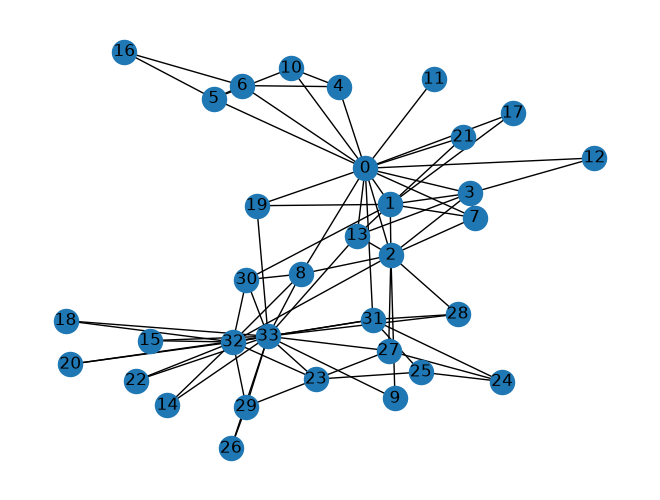

In [28]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
G = nx.karate_club_graph()
n = G.number_of_nodes()
print("nodes:", n, "| edges:", G.number_of_edges())
nx.draw(G, with_labels=True)
plt.show()

# Adjacency matrix and Modularity matrix

* `A` is the adjacency matrix. A[i][j]=1 if nodes i and j are connected, else zero. NetworkX's karate club graph carries a default 'weight' attribute. To 'switch off' this weight attribute to get the binary adjacency matrix (1 if connected, else 0) needed  for this task, weight=None is passed.
* `k = A.sum(axis=1)` is the degree vector and `m = sum(k)/2` is the number of edges.
* **Modularity matrix:** `B = A - k kᵀ / (2m)`
* where k = (k1, . . . , kn)⊤ is the degree vector, that is ki is the degree of vertex vi. The first term, A, records the actual edges of the network. The second term, k kᵀ / (2m), encodes the expected number of edges between vertices i and j under the random null model.  Essentially this means that if `B[i][j] > 0`, vertices *i* and *j* are connected more than by just chance.


In [29]:
A = nx.to_numpy_array(G, weight=None)
k = A.sum(axis=1)
m = A.sum() / 2
B = A - np.outer(k, k) / (2 * m)

print("A shape:", A.shape, "\nm =", m)
print("B symmetric?", np.allclose(B, B.T))
print("rows of B sum to 0?", np.allclose(B.sum(axis=1), 0))

A shape: (34, 34) 
m = 78.0
B symmetric? True
rows of B sum to 0? True


# Two way Split
A 'guess' split function is made: `s ∈ {+1,-1}^n`

Basically, to see how good this guess is, modularity score(Modularity Q) is utilized:
`Q = sᵀ B s / 4m`

However, it's impossible to try all `2^n` combinations to see which `s` is best. Hence, a method where  s is 'relaxed' to any real unit vector is used. Then the problem becomes:

`max (∥s∥2=1) s⊤ Bs`

By the Rayleigh-Ritz theorem, `sᵀBs = Σ αᵢ² λᵢ` (a weighted average of the eigenvalues), so it can never exceed the largest eigenvalue `λ₁`, and it reaches `λ₁` exactly when `s` is the leading eigenvector `u₁`.
Then `s_i = +1` if `(u₁)_i > 0`, else `-1`.

`np.linalg.eigh` is for symmetric matrices to calculate eigenvalues and eigenvectors.

Note: Swapping all 1s and -1s in s gives the same Q because the minus' cancel. It's essentiall just swapping the group labels.



In [30]:
values, vectors = np.linalg.eigh(B)
lam1 = values[np.argmax(values)]                 
u1 = vectors[:,np.argmax(values)]               
s = np.where(u1 > 0, 1, -1)       

Q = s @ B @ s / (4 * m)
set1 = set(np.where(s == 1)[0].tolist())
set2 = set(G.nodes) - set1


print("largest eigenvalue:", round(lam1, 4))
print("group sizes:", len(set1), len(set2))
print("Q:", Q)


largest eigenvalue: 4.9771
group sizes: 16 18
Q: 0.37146614069691


Comparison with the real split: the nodes where our first split differs from Mr. Hi's actual group

In [31]:
true_hi = {v for v in G if G.nodes[v]['club'] == 'Mr. Hi'}
print(set1 ^ true_hi)   # prints {8}

{8}


# Recursive Bisection

To continue splitting into smaller groups, essentially the same thing is done in an iterated manner.To split a community C, that part of B with rows and columns in C (B_C) is taken and its leading eigenpair is computed.
* if `λ₁ ≤ 0` -> no split of C can increase modularity, so `C` stays as one community
* else split `C` by the sign of the eigenvector entries

Note: a tiny tolerance (`1e-10`) instead of exactly 0 is used because of floating-point error. I also realised that the eigh function gives the eigenvalues in ascending order, so we can just use index -1 instead of argmax as previously used.

In [32]:
def split(nodes, tol=1e-10):    #nodes is a list of node numbers that form one community
    """Tries to split a community based on leading eigenpair. Returns (group_a, group_b) or None."""
    if len(nodes) <= 1:
        return None
    B_C = B[np.ix_(nodes, nodes)]               
    vals, vecs = np.linalg.eigh(B_C)
    lam, vec = vals[-1], vecs[:, -1]           
    if lam <= tol:                              
        return None
    s_C = np.where(vec > 0, 1, -1)
    group_a = np.array(nodes)[s_C == 1].tolist()
    group_b = np.array(nodes)[s_C == -1].tolist()
    if len(group_a) == 0 or len(group_b) == 0:  # if nothing is actually split
        return None
    return sorted(group_a), sorted(group_b)

Note: The next segment is a place where I got stuck on for a really long time because the loop kept going infinitely. I used claude to debug and modify the code here, but I did try to do it myself and do understand why this works.


In [33]:
communities = [list(range(n))]
history = [communities]
while True:
    new_communities, changed = [], False
    for c in communities:
        result = split(c)
        if result is None:
            new_communities.append(c)
        else:
            new_communities.extend(result)
            changed = True
    if not changed:
        break
    communities = new_communities
    history.append(communities)



sᵀBs adds B_ij for pairs in the same group and subtracts it for pairs in different groups. Since all entries of B sum to 0, the "different" total equals minus the "same" total, so sᵀBs = 2 × (same-group sum). Then Q = sᵀBs / 4m gives (same-group sum) / 2m.

In [34]:
def Q_of(comms):
    return sum(B[np.ix_(c, c)].sum() for c in comms) / (2 * m)

Q_history = [Q_of(c) if len(c) > 1 else 0.0 for c in history]
for t, comms in enumerate(history):
    print(f"iteration {t}: {len(comms)} communities, sizes {sorted(map(len, comms), reverse=True)}, Q = {Q_history[t]:.4f}")

iteration 0: 1 communities, sizes [34], Q = 0.0000
iteration 1: 2 communities, sizes [18, 16], Q = 0.3715
iteration 2: 4 communities, sizes [13, 10, 6, 5], Q = 0.4081
iteration 3: 5 communities, sizes [13, 10, 5, 5, 1], Q = 0.4094


Iteration 0 is the whole graph (one community, `Q = 0`, as predicted by Corollary 1). Each later iteration is one round of splitting every community that still has a positive leading eigenvalue. The recursion ends when no community can be split any more.

The output here is:  
iteration 0: 1 communities, sizes [34], Q = 0.0000  
iteration 1: 2 communities, sizes [18, 16], Q = 0.3715  
iteration 2: 4 communities, sizes [13, 10, 6, 5], Q = 0.4081  
iteration 3: 5 communities, sizes [13, 10, 5, 5, 1], Q = 0.4094  

# Visualisation after each split
The layout is computed once with a fixed seed so the places don't change, only the colours do.  

why is node 11 a loner? It's probably because node 11's only neighbour is node 0, which is in a different community. At iteration 2, node 11 sits in the group {4, 5, 6, 10, 11, 16}, but it has no edges to any of those nodes, so inside that group it is connected less than chance to everyone.

Note: Claude.ai was used to help plot this as I was unsure of how to do it, but I do understand the code and the outputs. 

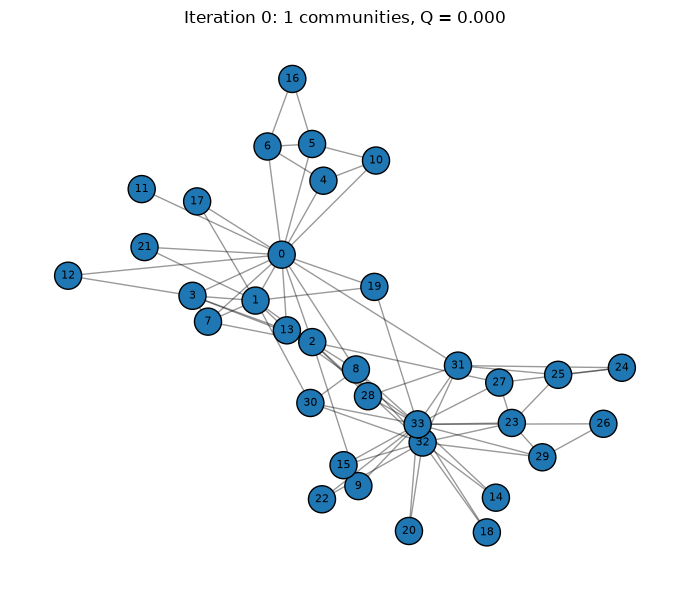

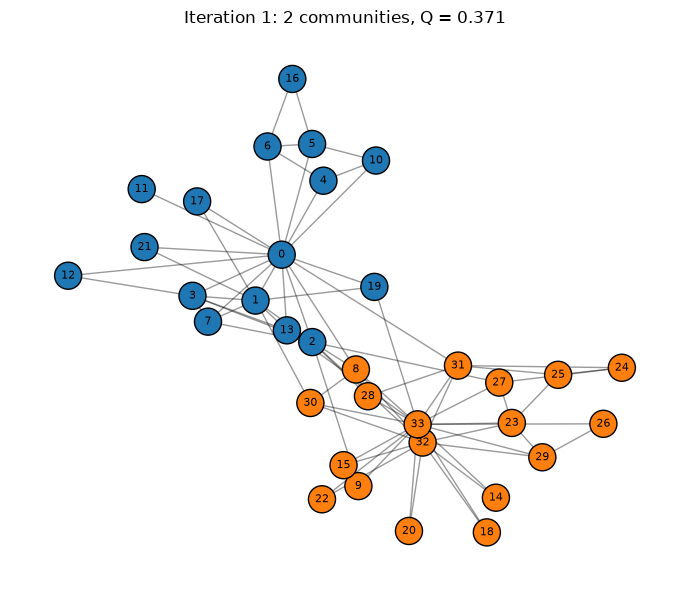

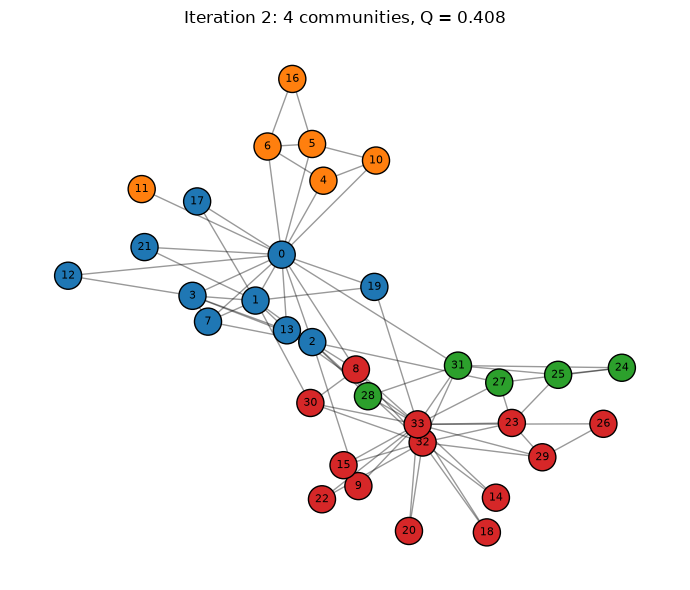

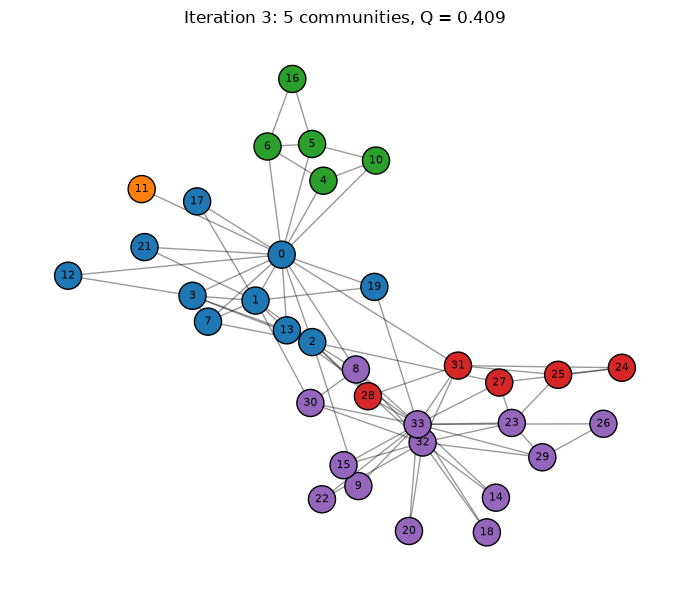

In [35]:
pos = nx.spring_layout(G, seed=42)             # fixed layout reused for every plot
palette = plt.cm.tab10.colors

for t, comms in enumerate(history):
    color_of = {}
    for ci, c in enumerate(comms):
        for v in c:
            color_of[v] = palette[ci % 10]
    plt.figure(figsize=(7, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, node_color=[color_of[v] for v in G.nodes], node_size=380, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8)
    plt.title(f"Iteration {t}: {len(comms)} communities, Q = {Q_history[t]:.3f}")
    plt.axis("off"); plt.tight_layout(); plt.show()

#  Node metrics after each split

**Node metrics to compute:**
* Degree centrality: using networkx.degree_centrality(G). Measures the fraction of nodes that are directly connected to i.
* Betweenness centrality: using networkx.betweenness_centrality(G).Counts how often node i lies on shortest paths between other nodes. 
* Closeness centrality: using networkx.closeness_centrality(G). Inverse of the average shortest-path distance from i to all other nodes.
* Clustering coefficient: using networkx.clustering(G). Fraction of a node’s neighbors that are also connected to each other.

Each node is measured inside its own community, not in the whole graph, otherwise the values would never change between iterations (if applied to G)

In [36]:
metric_funcs = {
    "degree":      nx.degree_centrality,
    "betweenness": nx.betweenness_centrality,
    "closeness":   nx.closeness_centrality,
    "clustering":  nx.clustering,
}


metrics = {name: {} for name in metric_funcs}
for t, comms in enumerate(history):
    for name, f in metric_funcs.items():
        vals = np.zeros(n)
        for c in comms:
            if len(c) < 2:
                continue
            sub = G.subgraph(c)
            res = f(sub)
            for v in c:
                vals[v] = res[v]
        metrics[name][t] = vals

#'Sanity check' (Claude's idea)
# quick look: top-5 nodes per metric at the final iteration (not the average, which is plotted later)
last = len(history) - 1
for name in metric_funcs:
    top = np.argsort(-metrics[name][last])[:5]
    print(f"{name:12s} top-5 at iteration {last}:", top.tolist())

degree       top-5 at iteration 3: [0, 33, 1, 32, 24]
betweenness  top-5 at iteration 3: [33, 24, 31, 0, 32]
closeness    top-5 at iteration 3: [0, 33, 1, 32, 24]
clustering   top-5 at iteration 3: [7, 13, 14, 15, 12]


# How the metrics are evolving
For each metric the value of every node (one line per node, 34 in total) is plotted against the iteration number.
Initially all the nodes were drawn and given different colours but the graph was too cramped. So I changed it- the 5 nodes with the highest average value across all iterations are drawn in colour and labelled; the other 29 nodes are drawn faint and transparent so the overall pattern is still visible.
Note: AI was used in this section to help with plotting.
Note 2: I was originally very confused and could not understand what was wrong with the clustering graph, and why it has only 1 coloured node instead of 5, and was trying out different ways to plot it as I thought I'd made a mistake. It is because nodes 7, 12, 14, 15 and 20 overlap because they all stay at 1.0 Also, nodes were ranked by average values across the iterations.

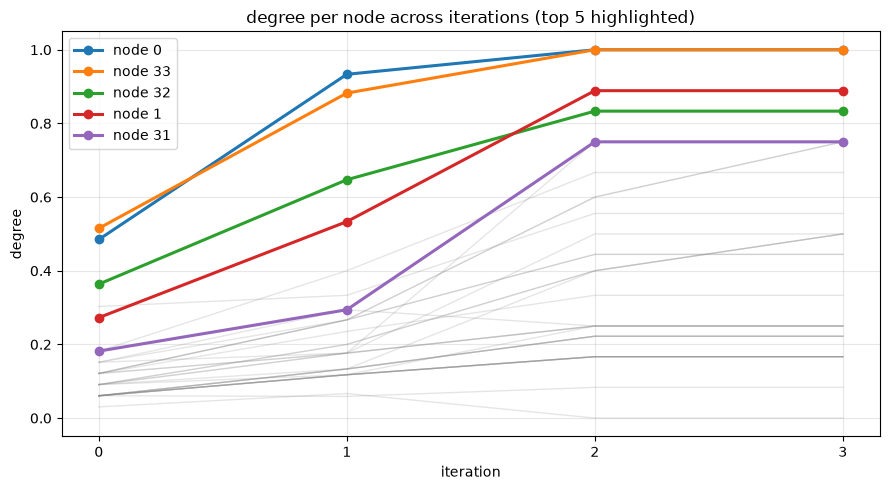

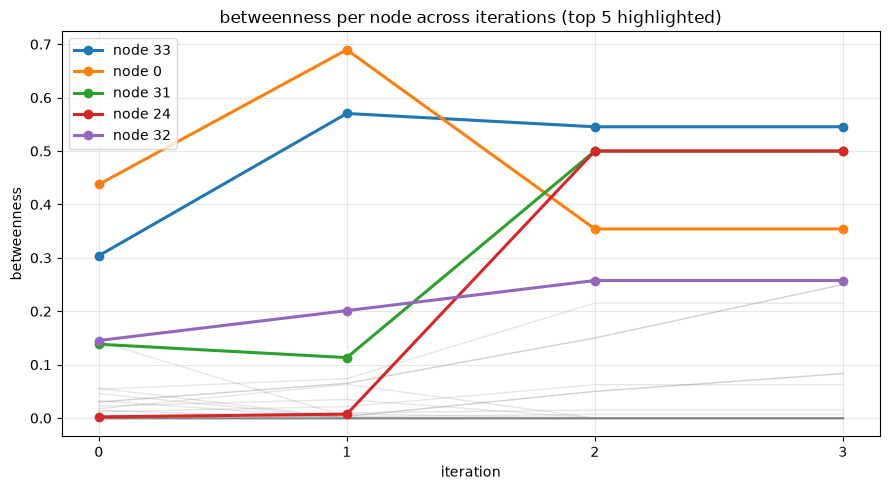

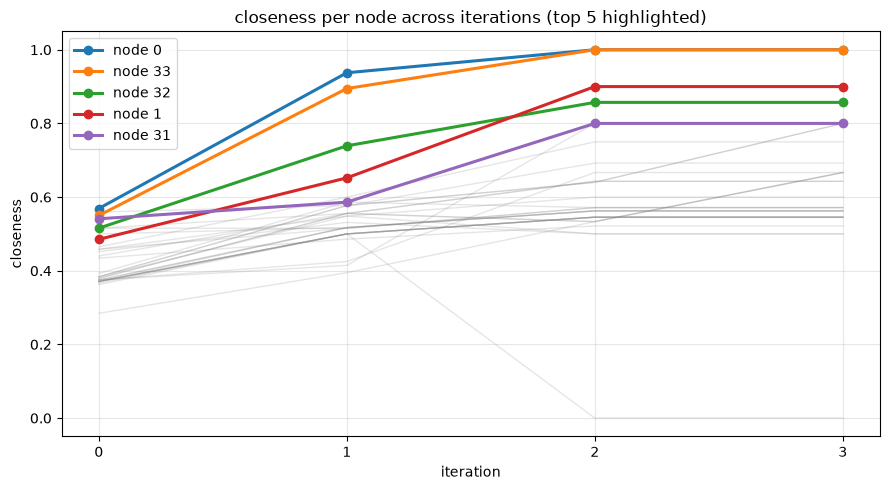

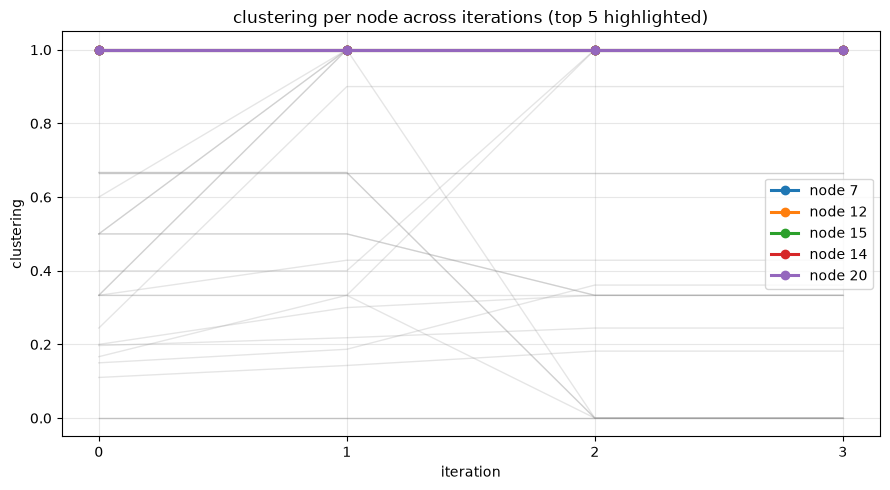

In [37]:
iters = list(range(len(history)))
colors = plt.cm.tab10.colors

for name in metric_funcs:
    series = np.array([metrics[name][t] for t in iters]).T     
    top5 = np.argsort(-series.mean(axis=1))[:5]                
    plt.figure(figsize=(9, 5))
    for v in range(n):
        if v not in top5:
            plt.plot(iters, series[v], color="gray", alpha=0.2, linewidth=1)
    for rank, v in enumerate(top5):
        plt.plot(iters, series[v], color=colors[rank], marker="o", linewidth=2.2, label=f"node {v}")
    plt.title(f"{name} per node across iterations (top 5 highlighted)")
    plt.xlabel("iteration"); plt.ylabel(name); plt.xticks(iters)
    plt.grid(alpha=0.3); plt.legend()
    plt.tight_layout(); plt.show()

# Discussion:
The recursive spectral method starts with the whole Karate Club graph. It is split in three rounds, ending with 5 communities. The first split gives two groups of 16 and 18 nodes with Q = 0.371, which matches the real division of the club except for node 8(Zachary's own analysis of this network predicted the split correctly for every member except one). Q then rises to 0.408 and 0.409 and flattens. The recursion stops when every community has a leading eigenvalue ≤ 0, so no further split can increase modularity. (Following the handout, I used the plain block of B for each community, which is probably why the last split makes node 11 a loner for small gains?)

**Central nodes:** Nodes 0 and 33, the two club leaders, stay near the top for degree and closeness at every iteration, and node 33 ends with the highest betweenness. Node 0's betweenness first rises (0.44 to 0.69), because inside its half of the club it connects most of the other members, and then falls (0.35) once its community is divided. Metrics were computed on each community's induced subgraph, so they change with each split.

**Effect of community structure:** Degree and closeness are normalised by the size of the graph, so they jump when a node is measured inside a smaller community (node 0's degree centrality goes 0.49 to 0.93 then to 1.0). So the raw values don't have much of a meaning, the rankings across the iterations do. Bridge nodes lose betweenness because the edges between communities are removed: node 2 drops from 0.14 to about 0 after the first split. Clustering rises for nodes whose neighbours are all in the same community. Nodes 7, 12, 14, 15 and 20 sit at 1.0 throughout, because splitting never cuts their 'triangles'.

To conclude, recursive spectral bisection recovers the two real factions almost identically (except for node 8) and then splits them into smaller communities, with Q at about 0.41 once no community has a positive leading eigenvalue. Nodes 0 and 33 remain the most central throughout, but what the metrics measure changes as the graph is divided: in the whole graph they reflect a node's global position, and inside a community they reflect its local role.


# References:
* Newman (2006), “Modularity and community structure in networks,” PNAS 103(23):8577–8582.
* Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. Journal of Anthropological Research, 33(4), 452-473.
